In [1]:
from pathlib import Path 
import os
import dotenv
dotenv.load_dotenv()
os.chdir(Path(os.getenv("PYTHONPATH")).expanduser())

In [2]:
import pandas as pd
import time
import numpy as np
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from skorch import NeuralNetRegressor
import torch
import torch.nn as nn
from src.model.ESN import ESNRegressor

In [3]:
df = pd.read_pickle('data/lorenz_data.pkl')
df.drop(columns=["dt_min", "t_max"], inplace=True)
df.head()

,t,x,y,z
0,0.000,-7.906697,-14.129764,-16.306456
1,0.001,-7.968928,-14.465952,-16.151253
2,0.002,-8.033898,-14.803325,-15.992904
3,0.003,-8.101592,-15.141956,-15.831328
4,0.004,-8.171996,-15.481917,-15.666437


In [4]:
STRIDE = 100
df_strides = df[ ::STRIDE ].reset_index(drop=True)

In [5]:
df_strides.head()

,t,x,y,z
0,0.0,-7.906697,-14.129764,-16.306456
1,0.1,-24.672225,-42.914606,35.172661
2,0.2,-10.285805,23.156058,48.685025
3,0.3,10.837283,18.620737,42.387750
4,0.4,8.634182,0.248069,41.103149


In [6]:
df_strides[100:105]

,t,x,y,z
100,10.0,5.621907,7.848892,21.957250
101,10.1,8.172017,11.064759,22.585364
102,10.2,10.855023,12.750135,27.747833
103,10.3,10.888821,8.897440,32.231589
104,10.4,7.908417,4.722127,30.117574


In [7]:
df_strides = df_strides[100:].reset_index(drop=True)
df_strides.head()

,t,x,y,z
0,10.0,5.621907,7.848892,21.957250
1,10.1,8.172017,11.064759,22.585364
2,10.2,10.855023,12.750135,27.747833
3,10.3,10.888821,8.897440,32.231589
4,10.4,7.908417,4.722127,30.117574


In [8]:
rng = np.random.default_rng(0)
torch.manual_seed(0)
np.random.seed(0)
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
data = df_strides.to_numpy(dtype=np.float32)


In [9]:
from src.data import LorenzWindowViewDataset, ToSkorchXY
from src.util import build_windows, split_indices
from torch.utils.data import DataLoader

TRAIN_RATIO = 0.7
TRAIN_N = int(2000 / TRAIN_RATIO) + 1
series = df_strides[["x", "y", "z"]].to_numpy(dtype=np.float32) 
dev_series = series[:TRAIN_N]    # (T, 3)
D = dev_series.shape[1]        # 3
WARM, XLEN = 5, 55
windows = build_windows(dev_series, warm_length=WARM, x_length=XLEN)   # (N, W+X+1, 3) view
N = windows.shape[0]
# --- split into *indices* (not materialized arrays) ---
idx = np.arange(N)
train_idx, val_idx = idx[:int(TRAIN_N * TRAIN_RATIO)], idx[int(TRAIN_N * TRAIN_RATIO):]

mu  = windows[train_idx].reshape(-1, D).mean(axis=0).astype(np.float32)
sd  = windows[train_idx].reshape(-1, D).std(axis=0).astype(np.float32)
sd  = np.where(sd == 0.0, 1.0, sd)  # guard against zeros

train_ds = ToSkorchXY(LorenzWindowViewDataset(
    window_view=windows, indices=train_idx, warm_length=WARM, x_length=XLEN,
    standardize=True, mean=mu, std=sd
))
val_ds = ToSkorchXY(LorenzWindowViewDataset(
    window_view=windows, indices=val_idx, warm_length=WARM, x_length=XLEN,
    standardize=True, mean=mu, std=sd
))


net = NeuralNetRegressor(
    ESNRegressor,
    module__input_size=3,
    module__output_size=3,
    module__reservoir_size=500,
    module__leak=0.7,
    module__spectral_radius=0.9,
    module__input_scale=0.8,
    module__bias_scale=0.0,
    module__sparsity=0.05,
    module__activation='tanh',
    module__seed=42,
    criterion=nn.MSELoss,
    optimizer=torch.optim.Adam,
    optimizer__lr=2e-3,
    max_epochs=12,
    batch_size=256,
    train_split=None,              # no internal val split
    iterator_train__shuffle=False, # keep time order
    device=device,
    verbose=0,
)

# Train with skorch
#net.fit(train_ds, y=None)

In [ ]:
# --- PREREQS (already built earlier) ------------------------------------------
# series:         np.ndarray (T, D) in ORIGINAL scale (float32)
# wins:           sliding_window_view(series, TOTAL=WARM+XLEN+1, axis=0)  -> (N, TOTAL, D)
# train_idx, val_idx: index arrays into wins (contiguous split recommended)
# mu, sd:         per-feature train-only mean/std (float32), shape (D,)
# WARM, XLEN:     warm and x lengths (e.g., 10, 100)

import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset
from skorch import NeuralNetRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_squared_error

def ds_to_arrays(ds):
    Xs, Ys = [], []
    for i in range(len(ds)):
        X_i, y_i = ds[i]
        Xs.append(X_i.numpy())
        Ys.append(y_i.numpy())
    return np.stack(Xs, 0), np.stack(Ys, 0)

param_distributions = {
    'module__reservoir_size': [700, 1000, 1200, 1500],
    'module__leak': [0.90, 0.95, 1.0],              # (add 0.3, 0.5 if supported)
    'module__spectral_radius': [0.85, 1.0],    # (add 1.1, 1.2 if supported)
    'module__input_scale': [0.6, 0.9, 1.0],
    'module__sparsity': [0.03],
    'optimizer__lr': [1e-3, 2e-3],
    'optimizer__weight_decay': [1e-4],
    'batch_size': [32, 64],
    'max_epochs': [25],
}



cv = TimeSeriesSplit(n_splits=2)
'''
gs = RandomizedSearchCV(
    net,
    param_distributions=param_distributions,
    n_iter=200,                          # cut if you want faster search
    cv=cv,
    scoring='neg_mean_squared_error',   # standardized target space
    refit=True,
    n_jobs=-1,
    verbose=1,
    random_state=0
)
'''
# standardize ToConcatWarmWindowView outputs on the fly
def ds_to_arrays_std(ds, mu, sd):
    Xs, Ys = [], []
    for i in range(len(ds)):
        X_i, y_i = ds[i]             # original scale tensors
        X_i = (X_i.numpy() - mu) / sd
        y_i = (y_i.numpy() - mu) / sd
        Xs.append(X_i); Ys.append(y_i)
    return np.stack(Xs, 0), np.stack(Ys, 0)
'''
X_train, y_train = ds_to_arrays(train_ds)
X_val,   y_val   = ds_to_arrays(val_ds)

# fit search exactly as you have it...
gs.fit(X_train, y_train)
'''
def ds_to_arrays_k(ds, series, WARM, XLEN, k, mu, sd):
    Xs, Ys = [], []
    T = series.shape[0]
    for i, s in enumerate(ds.starts):
        tgt = s + WARM + XLEN + (k - 1)
        if tgt >= T:
            break  # drop tail samples that don't have k-step future
        X_i, _ = ds[i]                  # tensors, original space
        X_i = (X_i.numpy() - mu) / sd   # std inputs
        y_k = (series[tgt] - mu) / sd   # std k-step target
        Xs.append(X_i); Ys.append(y_k)
    return np.stack(Xs, 0), np.stack(Ys, 0)

def ds_to_arrays_k_stride1(ds, k, mu, sd):
    """
    Build inputs X and K-ahead targets y from a stride-1, contiguous dataset ds
    that currently yields (X_i, y_1_i) pairs.

    Keeps only the first N-(k-1) samples so that y_k exists.
    Returns standardized arrays suitable for skorch.fit: X: (N', L, D), y: (N', D)
    """
    Xs, Ys = [], []
    N = len(ds)
    stop = N - (k - 1)
    if stop <= 0:
        raise ValueError(f"Dataset too short for k={k}: len(ds)={N}")

    for i in range(stop):
        X_i, _y1 = ds[i]                  # tensors, original scale
        _X_shift, y_k = ds[i + (k - 1)]   # future sample's 1-step target == our k-ahead

        Xs.append((X_i.numpy() - mu) / sd)
        Ys.append((y_k.numpy() - mu) / sd)

    return np.stack(Xs, 0), np.stack(Ys, 0)

K = 11
X_train_k, y_train_k = ds_to_arrays_k_stride1(train_ds, K, mu, sd)
X_val_k,   y_val_k   = ds_to_arrays_k_stride1(val_ds,   K, mu, sd)

def h11_direct_scorer(est, X, y):
    y_pred = est.predict(X).astype(np.float32)
    return -mean_squared_error(y, y_pred)  # sklearn maximizes score

cv = TimeSeriesSplit(n_splits=2)

gs = RandomizedSearchCV(
    net,
    param_distributions=param_distributions,
    n_iter=2,
    cv=cv,
    scoring={'h11': h11_direct_scorer},
    refit='h11',
    n_jobs=-1,
    verbose=1,
    random_state=0,
    
)

gs.fit(X_train_k, y_train_k)

# original-space metrics
from sklearn.metrics import mean_squared_error
def inv(z): return z * sd + mu

# rollout in std space, invert once
def rollout_std(est, start_window_orig, steps):
    cur = (start_window_orig - mu) / sd
    preds = []
    for _ in range(steps):
        y_next = est.predict(cur[None, ...]).astype(np.float32)[0]
        preds.append(y_next)
        cur = np.concatenate([cur[1:], y_next[None, :]], axis=0)
    return inv(np.stack(preds, 0))


Fitting 2 folds for each of 2 candidates, totalling 4 fits


In [11]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Return STANDARDIZED predictions
def rollout_std(est, start_window_orig, steps):
    cur = (start_window_orig - mu) / sd
    preds_std = []
    for _ in range(steps):
        y_next_std = est.predict(cur[None, ...]).astype(np.float32)[0]
        preds_std.append(y_next_std)
        cur = np.concatenate([cur[1:], y_next_std[None, :]], axis=0)
    return np.stack(preds_std, axis=0)  # <-- standardized

# 10-step rollout (STANDARDIZED)
abs_i0 = int(val_idx[0])
start_window_orig = windows[abs_i0, :WARM+XLEN, :]
K = 10
preds_std = rollout_std(gs, start_window_orig, K)
gt_std = (dev_series[abs_i0 + WARM + XLEN : abs_i0 + WARM + XLEN + K] - mu) / sd


print(f"{K}-step rollout MSE (std):", mean_squared_error(gt_std, preds_std))
print("per-dim MSE:", mean_squared_error(gt_std, preds_std, multioutput="raw_values"))
print("R² per dim:", r2_score(gt_std, preds_std, multioutput="raw_values"))


10-step rollout MSE (std): 1.3145668506622314
per-dim MSE: [0.93469656 1.1274408  1.8815632 ]
R² per dim: [-0.16190434  0.02252024 -0.7332959 ]


In [14]:
import pandas as pd
cv = pd.DataFrame(gs.cv_results_)
view = (cv[["rank_test_h11","mean_test_h11","std_test_h11","params"]]
        .sort_values("rank_test_h11")
        .assign(mean_test_MSE=lambda d: -d["mean_test_h11"]))
print(view.head(10).to_string(index=False))


 rank_test_h11  mean_test_h11  std_test_h11                                                                                                                                                                                                                                       params  mean_test_MSE
             1      -0.014906      0.001041 {'optimizer__weight_decay': 0.0001, 'optimizer__lr': 0.001, 'module__spectral_radius': 0.85, 'module__sparsity': 0.03, 'module__reservoir_size': 1500, 'module__leak': 0.95, 'module__input_scale': 0.6, 'max_epochs': 25, 'batch_size': 64}       0.014906
             2      -0.030929      0.008315   {'optimizer__weight_decay': 0.0001, 'optimizer__lr': 0.002, 'module__spectral_radius': 1.0, 'module__sparsity': 0.03, 'module__reservoir_size': 1500, 'module__leak': 1.0, 'module__input_scale': 0.6, 'max_epochs': 25, 'batch_size': 32}       0.030929


In [ ]:
best_net = gs.best_estimator_



In [ ]:
def rollout_evaluation(best_net, windows, val_idx, K=11):
    rollout_stats = []
    for start_idx in val_idx:
        if start_idx + WARM + XLEN + K > len(dev_series):
            continue
        start_window_orig = windows[start_idx, :WARM+XLEN, :]
        preds_std = rollout_std(best_net, start_window_orig, K)
        gt_std = (dev_series[start_idx + WARM + XLEN : start_idx + WARM + XLEN + K] - mu) / sd
        #print(f"Start idx {start_idx}:")
        mean_sq_err = mean_squared_error(gt_std, preds_std)
        r2_scr = r2_score(gt_std, preds_std, multioutput="raw_values")
        rollout_stats.append({
            "start_idx": start_idx,
            "mse": mean_sq_err,
            "r2": r2_scr,
        })
    return pd.DataFrame(rollout_stats)
    #print(f"  {K}-step rollout MSE (std):", mean_squared_error(gt_std, preds_std))
    #print("  per-dim MSE:", mean_squared_error(gt_std, preds_std, multioutput="raw_values"))
    #print("  R² per dim:", r2_score(gt_std, preds_std, multioutput="raw_values"))



In [ ]:
rollout_stats_df = rollout_evaluation(best_net, windows, val_idx, K=11)

In [ ]:
rollout_stats_df = rollout_stats_df.sort_values("start_idx").reset_index(drop=True)
rollout_stats_df.head()
rollout_stats_df["mse"].mean()

0.7506401729722729

In [ ]:
from sklearn.base import clone

res   = gs.cv_results_
ranks = np.array(res["rank_test_score"])   # 1 = best, 2 = second-best, ...
i2    = int(np.where(ranks == 2)[0])       # index of the second-best config
params2 = res["params"][i2]

base = gs.estimator                 # NOT best_estimator_ (that already has best params)
second_best = clone(base).set_params(**params2)

second_best.fit(X_train, y_train)

/var/folders/jg/j77njgmn2ts9wkln0x_x_vcc0000gn/T/ipykernel_6720/1113212238.py:5: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  i2    = int(np.where(ranks == 2)[0])       # index of the second-best config


,module,<class 'src.m...ESNRegressor'>
,criterion,<class 'torch...loss.MSELoss'>
,optimizer,<class 'torch...im.adam.Adam'>
,lr,0.01
,max_epochs,25
,batch_size,32
,iterator_train,<class 'torch...r.DataLoader'>
,iterator_valid,<class 'torch...r.DataLoader'>
,dataset,<class 'skorc...aset.Dataset'>
,train_split,None
,callbacks,None


In [ ]:
sec_best_rollout_stats_df = rollout_evaluation(second_best, windows, val_idx, K=11)

In [ ]:
rollout_stats_df["mse"].mean()

0.7506401729722729

In [ ]:
net3 = NeuralNetRegressor(
    ESNRegressor,
    module__input_size=3,
    module__output_size=3,
    module__reservoir_size=1200,
    module__leak=0.9,
    module__spectral_radius=1.0,
    module__input_scale=0.9,
    module__bias_scale=0.0,
    module__sparsity=0.05,
    module__activation='tanh',
    module__seed=42,
    criterion=nn.MSELoss,
    optimizer=torch.optim.Adam,
    optimizer__lr=2e-3,
    optimizer__weight_decay=1e-4,   # 0.0001
    max_epochs=25,
    batch_size=64,
    train_split=None,               # no internal val split
    iterator_train__shuffle=False,  # keep time order
    device=device,
    verbose=0,
)

net3.fit(X_train, y_train)

,module,<class 'src.m...ESNRegressor'>
,criterion,<class 'torch...loss.MSELoss'>
,optimizer,<class 'torch...im.adam.Adam'>
,lr,0.01
,max_epochs,25
,batch_size,64
,iterator_train,<class 'torch...r.DataLoader'>
,iterator_valid,<class 'torch...r.DataLoader'>
,dataset,<class 'skorc...aset.Dataset'>
,train_split,None
,callbacks,None


In [ ]:
net3_rollout_stats_df = rollout_evaluation(net3, windows, val_idx, K=11)

In [ ]:
net3_rollout_stats_df["mse"].mean()

0.36919746636667145

In [ ]:
rollout_preds = rollout_std(
    net3,
    windows[val_idx[0], :WARM+XLEN, :],
    40000
)
rollout_preds_df = pd.DataFrame(rollout_preds, columns=["x", "y", "z"])

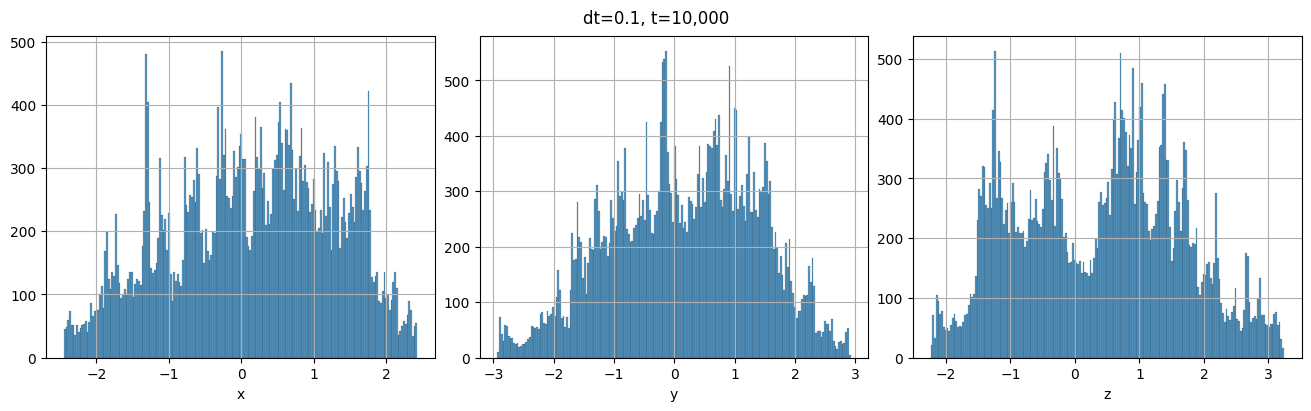

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

labels = {0: 'x', 1: 'y', 2: 'z'}
fig, axs = plt.subplots(1, 3, layout='constrained', figsize=(13, 4))
for i, arr in enumerate([rollout_preds_df['x'], rollout_preds_df['y'], rollout_preds_df['z']]):
    sns.histplot(arr, bins=200, ax=axs[i])
    axs[i].set_xlabel(f'{labels[i]}')
    axs[i].set_ylabel('')
    axs[i].grid(True)
fig.suptitle(f'dt={0.1}, t={10_000:,}')
plt.show()